Step 1: Import Libraries and Load Dataset


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
# Load dataset
data = load_diabetes(as_frame=True)
df = data.frame
print(df.head())
print(df.describe())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-0

Step 2: Exploratory Data Analysis

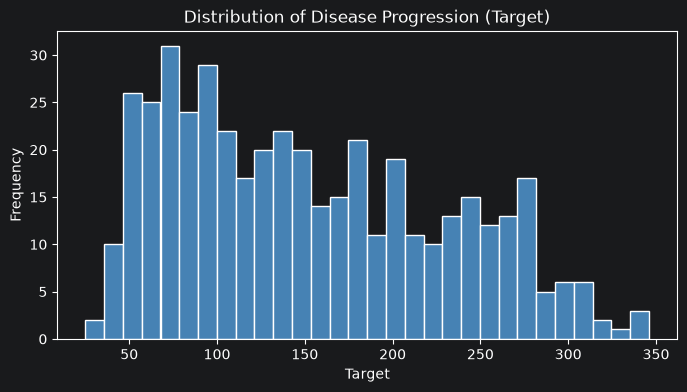

target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: target, dtype: float64


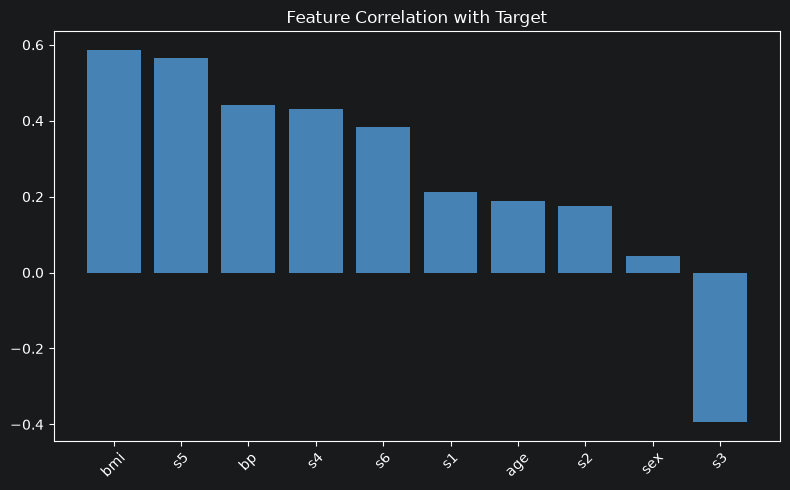

In [2]:
# Examine the target variable distribution
plt.figure(figsize=(8, 4))      
plt.hist(df['target'], bins=30, color='steelblue', edgecolor='white')
plt.title('Distribution of Disease Progression (Target)')
plt.xlabel('Target')
plt.ylabel('Frequency')
plt.show()
# Correlation of features with target
corr = df.corr()['target'].sort_values(ascending=False)
print(corr)
plt.figure(figsize=(8, 5))
plt.bar(corr.index[1:], corr.values[1:], color='steelblue')
plt.xticks(rotation=45)
plt.title('Feature Correlation with Target')
plt.tight_layout()
plt.show()

Step 3: Data Preprocessing

In [3]:
# Features and target (all 10 features used)
X = df.drop(columns=['target']).values
y = df['target'].values
# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42)
# Feature scaling (important for Ridge/Lasso since penalty depends on coefficient scale)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

Step 4: Baseline — Standard Linear Regression

In [4]:
lin_model = LinearRegression()
lin_model.fit(X_train_sc, y_train)
y_pred_lin = lin_model.predict(X_test_sc)
mse_lin = mean_squared_error(y_test, y_pred_lin)
r2_lin = r2_score(y_test, y_pred_lin)
print(f'Linear Regression => MSE={mse_lin:.4f} RMSE={mse_lin**0.5:.4f} R2={r2_lin:.4f}')
#print('Coefficients:', np.round(lin_model.coef_, 2)

Linear Regression => MSE=2900.1936 RMSE=53.8534 R2=0.4526


In [ ]:
Step 5: Ridge and Lasso Regression with Cross-Validation

In [5]:
alphas = np.logspace(-3, 2, 50) # candidate alpha values: 0.001 to 100
# RidgeCV and LassoCV perform built-in k-fold cross-validation
ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train_sc, y_train)
print(f'Best alpha (Ridge): {ridge_cv.alpha_:.4f}')
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000)
lasso_cv.fit(X_train_sc, y_train)
print(f'Best alpha (Lasso): {lasso_cv.alpha_:.4f}')
# Refit final models using the tuned alpha (RidgeCV/LassoCV already store the fitted estimator)
ridge_model = Ridge(alpha=ridge_cv.alpha_).fit(X_train_sc, y_train)
lasso_model = Lasso(alpha=lasso_cv.alpha_, max_iter=10000).fit(X_train_sc, y_train)

Best alpha (Ridge): 39.0694
Best alpha (Lasso): 1.4563


Step 6: Compare Performance Metrics

In [6]:
models = {
'Linear Regression': lin_model,
'Ridge Regression': ridge_model,
'Lasso Regression': lasso_model,
}
results = []
for name, model in models.items():
    y_pred = model.predict(X_test_sc)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append((name, mse, mse**0.5, r2))
    #print(f'{name:20s} MSE={mse:.4f} RMSE={mse**0.5:.4f} R2={r2:.4f}')
results_df = pd.DataFrame(results, columns=['Model', 'MSE', 'RMSE', 'R2'])
print(results_df)

               Model          MSE       RMSE        R2
0  Linear Regression  2900.193628  53.853446  0.452603
1   Ridge Regression  2858.601520  53.465891  0.460453
2   Lasso Regression  2803.433565  52.947460  0.470866


Step 7: Visualization — Coefficients and Model Comparison

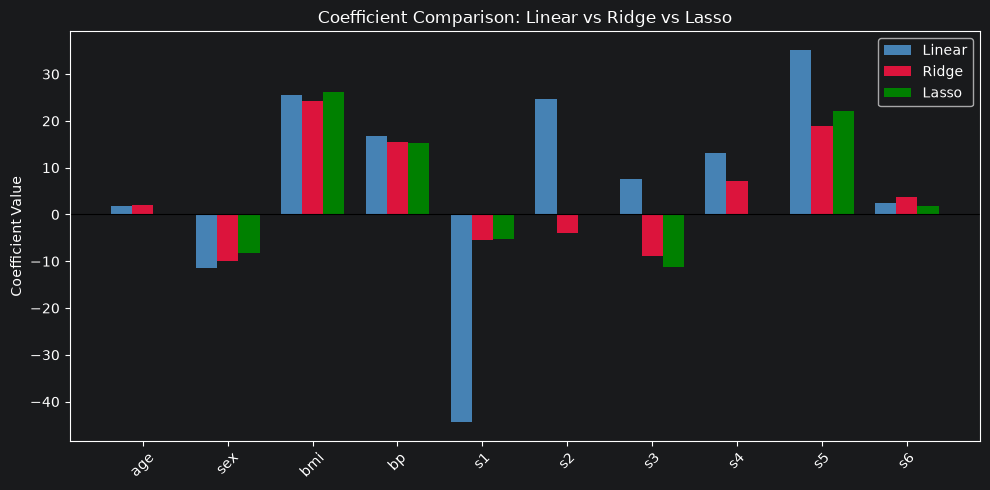

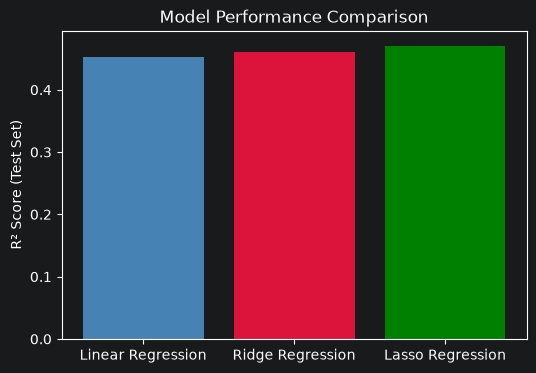

In [8]:
feature_names = df.drop(columns=['target']).columns
fig, ax = plt.subplots(figsize=(10, 5))
x_pos = np.arange(len(feature_names))
width = 0.25
ax.bar(x_pos - width, lin_model.coef_, width, label='Linear', color='steelblue')
ax.bar(x_pos, ridge_model.coef_, width, label='Ridge', color='crimson')
ax.bar(x_pos + width, lasso_model.coef_, width, label='Lasso', color='green')
ax.set_xticks(x_pos)
ax.set_xticklabels(feature_names, rotation=45)
ax.set_ylabel('Coefficient Value')
ax.set_title('Coefficient Comparison: Linear vs Ridge vs Lasso')
ax.legend()
ax.axhline(0, color='black', lw=0.8)
plt.tight_layout()
plt.show()
# Bar chart of R2 scores
plt.figure(figsize=(6, 4))
plt.bar(results_df['Model'], results_df['R2'], color=['steelblue', 'crimson', 'green'])
plt.ylabel('R² Score (Test Set)')
plt.title('Model Performance Comparison')
plt.show()